In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
sales_data=pd.read_csv("sales_data_csv.csv",)
sales_data = sales_data.drop(columns=['Unnamed: 0'])
sales_data

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,calculated_revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56,468.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,14996,2035-09-05,1289,Clothing,West,2,371.74,0.27,COD,3,2.3,542.74,542.74
4996,14997,2035-09-06,1294,Beauty,North,3,553.67,0.14,COD,11,2.2,1428.47,1428.47
4997,14998,2035-09-07,1450,Beauty,West,3,77.22,0.24,Wallet,6,3.4,176.06,176.06
4998,14999,2035-09-08,1903,Electronics,South,4,138.41,0.21,COD,4,2.8,437.38,437.38


In [33]:
total_revenue = sales_data['revenue'].sum()
print(f"Total Revenue: Rs. {total_revenue:,.2f}")

Total Revenue: Rs. 5,109,775.74


The total revenue represents the sum of revenue generated from all orders in the dataset.

In [34]:
total_orders = sales_data['order_id'].nunique()
print(f"Total Orders: {total_orders}")

Total Orders: 5000


In [6]:
unique_customers = sales_data['customer_id'].nunique()
print(f"There are {unique_customers} unique customers.")

There are 989 unique customers.


In [7]:
average_revenue_per_order = total_revenue/total_orders


In [8]:
total_quantity_sold = sales_data['quantity'].sum()


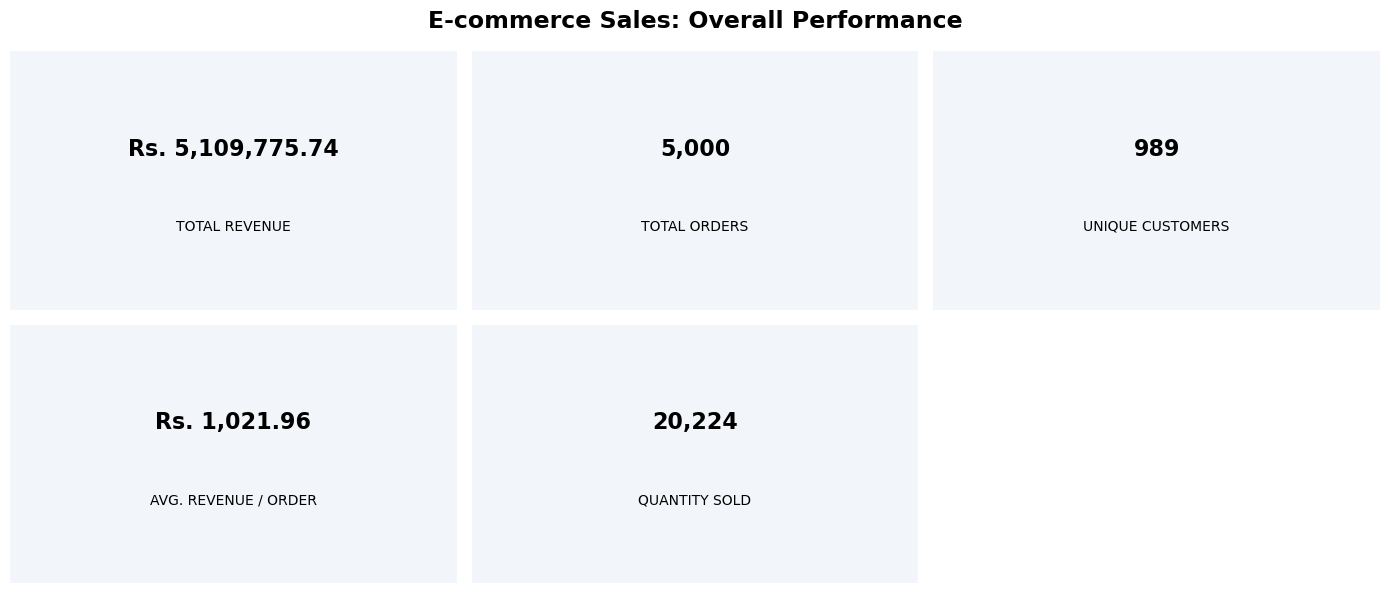

In [9]:


# Create KPI values
kpis = [
    ("TOTAL REVENUE", f"Rs. {total_revenue:,.2f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNIQUE CUSTOMERS", f"{unique_customers:,}"),
    ("AVG. REVENUE / ORDER", f"Rs. {average_revenue_per_order:,.2f}"),
    ("QUANTITY SOLD", f"{total_quantity_sold:,}")
]

fig,axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()

for i, (title, value) in enumerate(kpis):
    axes[i].set_facecolor("#F2F5F9")
    axes[i].text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=16, fontweight="bold",
        transform=axes[i].transAxes
    )
    axes[i].text(
        0.5, 0.32, title,
        ha="center", va="center",
        fontsize=10,
        transform=axes[i].transAxes
    )

    axes[i].set_xticks([])
    axes[i].set_yticks([])

    for spine in axes[i].spines.values():
        spine.set_visible(False)

# Hide the unused sixth card
axes[5].axis("off")

fig.suptitle(
    "E-commerce Sales: Overall Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


The summary of KPIs gives a brief description of the performance of the e-commerce business. The total revenue shows the income generated; total orders and unique customers represents sales activity, average revenue per order shows the income per transaction, while the total quantity sold shows the number of products sold.

In [117]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().round(2).sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

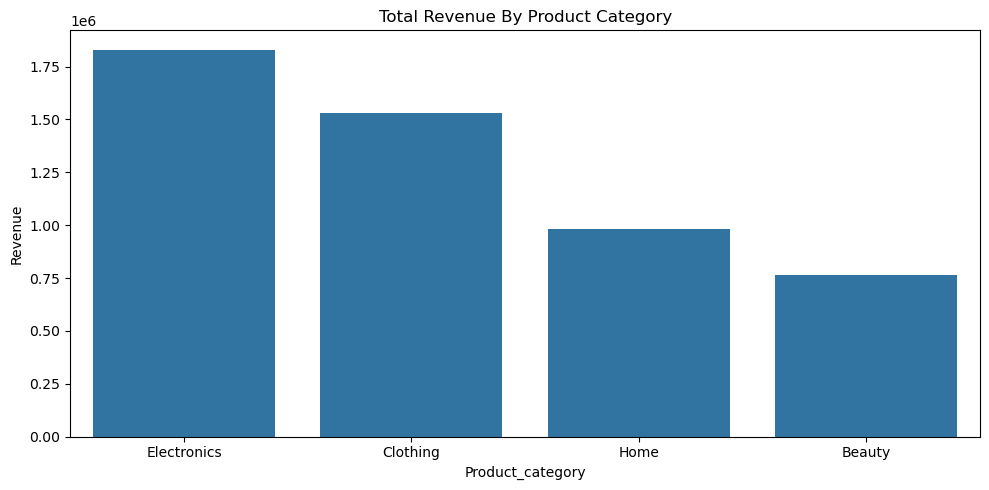

In [143]:
plt.figure(figsize=(10,5))
sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values)
plt.title('Total Revenue By Product Category')
plt.xlabel('Product_category')
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

In [119]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

In [138]:
monthly_revenue=sales_data.groupby(sales_data['order_date'].dt.month)['revenue'].sum().sort_values(ascending=False)
monthly_revenue

order_date
5     479772.55
8     460874.78
6     442941.58
7     440570.72
1     426374.92
3     425050.52
2     413890.24
11    410657.88
10    407873.12
9     402368.11
12    400686.16
4     398715.16
Name: revenue, dtype: float64

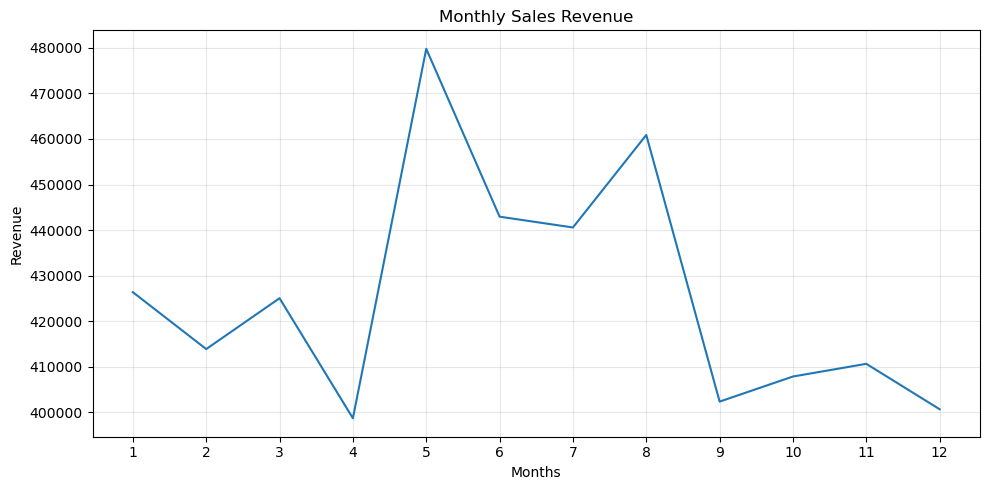

In [140]:
plt.figure(figsize=(10,5))
sns.lineplot(monthly_revenue)
plt.title("Monthly Sales Revenue")
plt.xlabel('Months')
plt.ylabel('Revenue')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

May generated the highest revenue, followed by August, while April had the lowest revenue. This shows that sales revenue varied from month to month. The business can look at what made May more successful and use those findings to improve sales during months with lower revenue.

In [122]:
Yearly_sales_revenue = sales_data.groupby(sales_data['order_date'].dt.year)['revenue'].sum().sort_values(ascending=False)
Yearly_sales_revenue

order_date
2033    408725.72
2030    387884.46
2032    386584.63
2026    386369.69
2027    386151.91
2028    376844.80
2022    371824.30
2023    365915.79
2031    365250.83
2034    363239.55
2024    363209.13
2029    359239.24
2025    349802.33
2035    238733.36
Name: revenue, dtype: float64

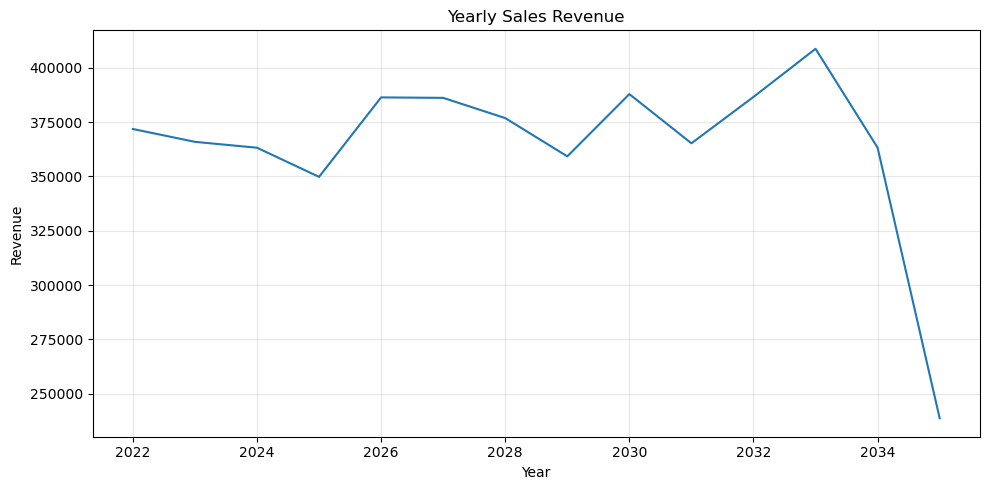

In [147]:
plt.figure(figsize=(10,5))
sns.lineplot(Yearly_sales_revenue)
plt.title('Yearly Sales Revenue')
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Yearly sales revenue went up and down over the years instead of showing steady growth. Revenue was highest in 2033 and lowest in 2035. The drop in revenue in 2035 suggests that the business should look into possible reasons for the decline and find ways to improve sales.

In [139]:
monthly_orders = sales_data.groupby(sales_data['order_date'].dt.month).order_id.nunique().sort_values(ascending=False)
monthly_orders

order_date
1     434
3     434
5     434
7     434
8     434
4     420
6     420
10    403
12    403
9     399
2     395
11    390
Name: order_id, dtype: int64

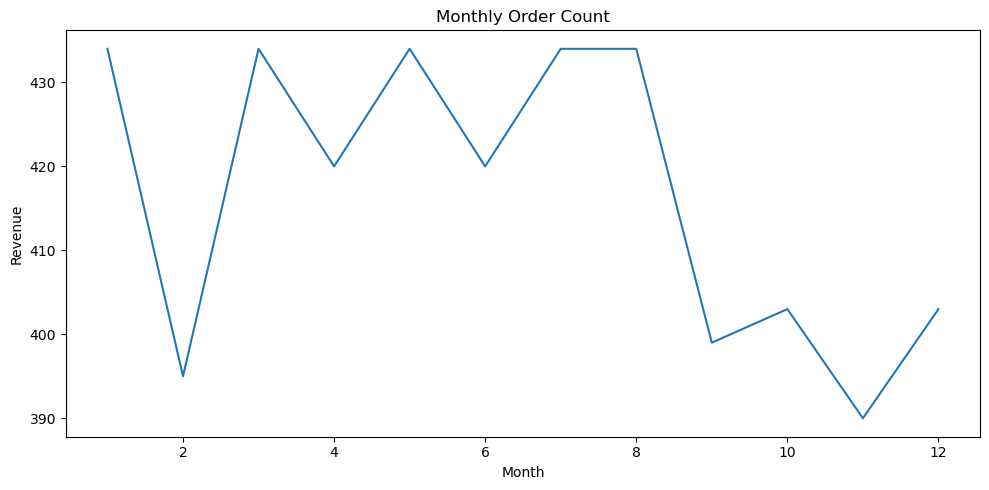

In [145]:
plt.figure(figsize=(10,5))
sns.lineplot(monthly_orders)
plt.title('Monthly Order Count')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()


January, March, May, July, and August had the highest number of orders, with 434 orders each. November had the fewest orders, with 390. Overall, the number of orders was fairly stable throughout the year, although November had slightly lower sales activity than the other months.

In [149]:
%cd ..

C:\Users\Dell\projects


In [146]:
# plt.figure(figsize=(10,5))
# plt.title('Monthly Order Count')
# sns.barplot(x=monthly_orders.index,y=monthly_orders.values)
# plt.xlabel('Months')
# plt.ylabel('Number of orders')
# plt.tight_layout()
# plt.show()

In [151]:
!git add ecommerce sal

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   ecommerce_sales_analysis/ecommerce_sales.csv
	modified:   ecommerce_sales_analysis/ecommerce_sales_analysis.ipynb
	deleted:    ecommerce_sales_analysis/ecommerce_sales_anlaysis.ipynb
	modified:   ecommerce_sales_analysis/ecommerce_sales_visualization.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	ecommerce_sales_analysis/.gitignore
	ecommerce_sales_analysis/README.md
	ecommerce_sales_analysis/netflix_data_analysis/
	ecommerce_sales_analysis/sales_data_csv.csv
	projects_repair_backup_20261015/

no changes added to commit (use "git add" and/or "git commit -a")
